In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

sns.set_style("whitegrid")
print("StreamGuard libraries imported successfully!")

StreamGuard libraries imported successfully!


In [2]:

data = pd.read_csv("netflix_users.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", data.shape)

display(data.head())

Dataset loaded successfully!
Dataset shape: (500, 9)


,user_id,age,avg_daily_watch_minutes,monthly_logins,avg_rating_given,subscription_months,monthly_fee_usd,support_tickets,churned
0,1001,25.0,116.1,20.0,3.64,27.0,14.51,2.0,0
1,1002,45.0,118.4,20.0,4.17,21.0,13.35,0.0,0
2,1003,39.0,98.1,21.0,2.40,12.0,7.60,3.0,0
3,1004,20.0,112.8,20.0,2.86,25.0,12.78,2.0,0
4,1005,40.0,113.8,16.0,3.65,29.0,16.79,1.0,0


In [3]:
print("Duplicate rows:", data.duplicated().sum())

data = data.drop_duplicates().copy()
data = data.fillna(0)

print("Missing values after cleaning:")
print(data.isnull().sum())

data.to_csv("netflix_users_cleaned.csv", index=False)

print("Data cleaning completed!")

Duplicate rows: 0
Missing values after cleaning:
user_id                    0
age                        0
avg_daily_watch_minutes    0
monthly_logins             0
avg_rating_given           0
subscription_months        0
monthly_fee_usd            0
support_tickets            0
churned                    0
dtype: int64
Data cleaning completed!


In [4]:
print("Dataset information:")
data.info()

print("Dataset shape:")
print(data.shape)

print("Data types:")
print(data.dtypes)

print("Unique values:")
print(data.nunique())

print("Statistical summary:")
display(data.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   user_id                  500 non-null    int64  
 1   age                      500 non-null    float64
 2   avg_daily_watch_minutes  500 non-null    float64
 3   monthly_logins           500 non-null    float64
 4   avg_rating_given         500 non-null    float64
 5   subscription_months      500 non-null    float64
 6   monthly_fee_usd          500 non-null    float64
 7   support_tickets          500 non-null    float64
 8   churned                  500 non-null    int64  
dtypes: float64(7), int64(2)
memory usage: 35.3 KB
Dataset shape:
(500, 9)
Data types:
user_id                      int64
age                        float64
avg_daily_watch_minutes    float64
monthly_logins             float64
avg_rating_given           float64
subscription_months        flo

,user_id,age,avg_daily_watch_minutes,monthly_logins,avg_rating_given,subscription_months,monthly_fee_usd,support_tickets,churned
count,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,1250.500000,30.686000,88.684200,18.01800,3.633760,20.036000,13.651620,1.682000,0.300000
std,144.481833,7.526267,37.052881,7.74504,0.786254,8.967024,2.590567,1.387345,0.458717
min,1001.000000,14.000000,0.000000,0.00000,1.330000,1.000000,7.070000,0.000000,0.000000
25%,1125.750000,26.000000,63.475000,13.00000,3.087500,14.000000,11.847500,1.000000,0.000000
50%,1250.500000,31.000000,94.400000,19.50000,3.650000,20.000000,13.510000,1.000000,0.000000
75%,1375.250000,36.000000,115.400000,24.00000,4.190000,26.000000,15.452500,3.000000,1.000000
max,1500.000000,50.000000,173.400000,35.00000,5.000000,45.000000,21.270000,6.000000,1.000000


In [5]:
features = [
    "age",
    "avg_daily_watch_minutes",
    "monthly_logins",
    "avg_rating_given",
    "subscription_months",
    "monthly_fee_usd",
    "support_tickets"
]

X = data[features]
y = data["churned"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
model = GaussianNB()
model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[280.,120.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.7,0.3]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.438e-06
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['age','avg_daily_watch_minutes','monthly_logins',..., 'subscription_months','monthly_fee_usd','support_tickets']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 7)","[[ 31.19,108.35, 22.08,..., 24.39, 13.21, 1.1 ], [ 29.13, 44.01, 8.82,..., 11.64, 15.11, 3.01]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 7)","[[ 54.93,541.91, 23.74,..., 50.54, 6.3 , 1.02], [ 67.03,629.93, 23.99,..., 40.45, 5.4 , 1.39]]"


In [7]:
print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model training completed!
Training records: 400
Testing records: 100


In [8]:
y_pred = model.predict(X_test)

print("MODEL EVALUATION")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 3))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL EVALUATION
Accuracy: 96.0 %
Precision: 0.933
Recall: 0.933
F1 Score: 0.933
Confusion Matrix:
[[68  2]
 [ 2 28]]
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        70
           1       0.93      0.93      0.93        30

    accuracy                           0.96       100
   macro avg       0.95      0.95      0.95       100
weighted avg       0.96      0.96      0.96       100



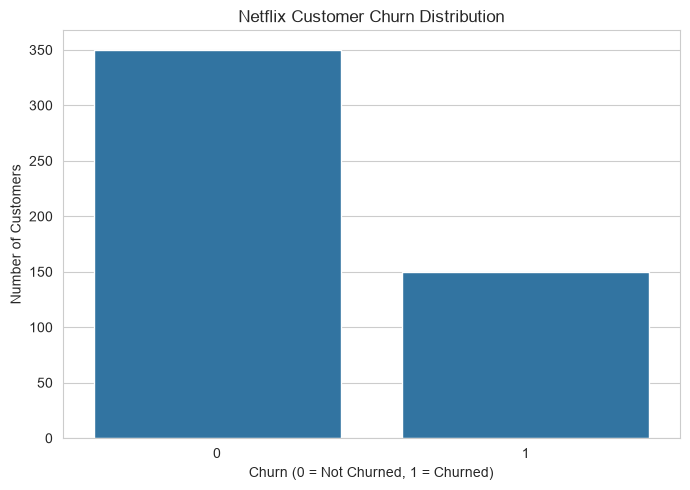

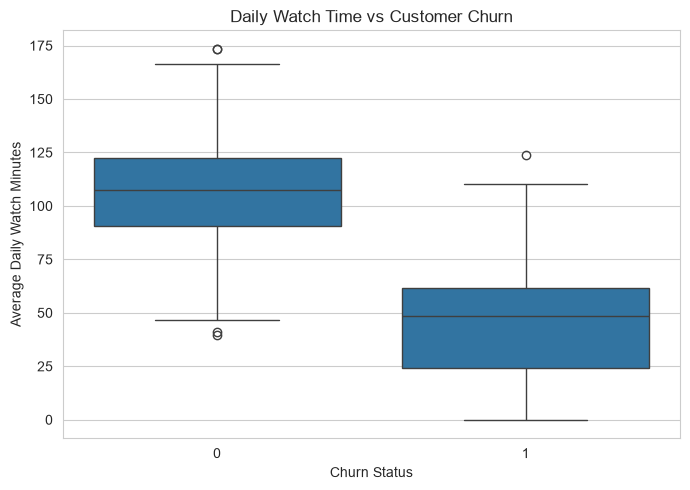

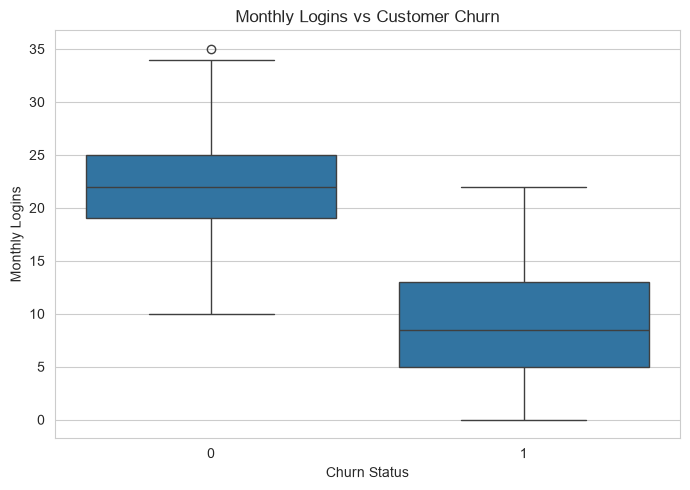

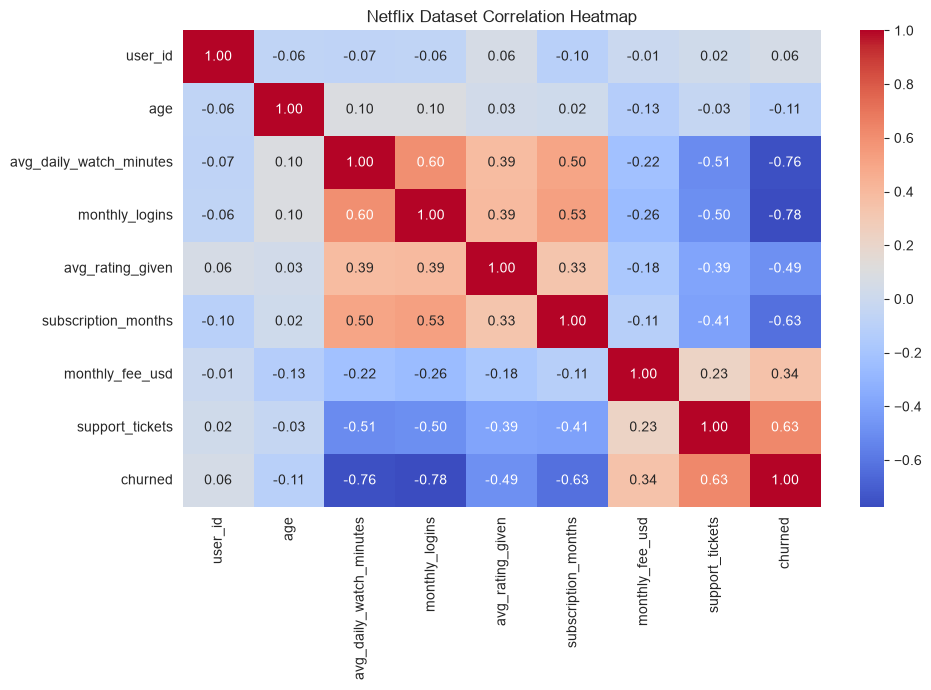

In [9]:
# Graph 1: Churn distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="churned")
plt.title("Netflix Customer Churn Distribution")
plt.xlabel("Churn (0 = Not Churned, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Graph 2: Watch time vs churn
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="churned", y="avg_daily_watch_minutes")
plt.title("Daily Watch Time vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Average Daily Watch Minutes")
plt.tight_layout()
plt.show()

# Graph 3: Monthly logins vs churn
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="churned", y="monthly_logins")
plt.title("Monthly Logins vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Logins")
plt.tight_layout()
plt.show()

# Graph 4: Correlation heatmap
plt.figure(figsize=(10, 7))
numeric_data = data.select_dtypes(include="number")
correlation = numeric_data.corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Netflix Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
print("=" * 45)
print("STREAMGUARD - CUSTOMER CHURN PREDICTION")
print("=" * 45)

age = float(input("Enter customer age: "))
watch_minutes = float(input("Enter average daily watch minutes: "))
monthly_logins = float(input("Enter monthly logins: "))
avg_rating = float(input("Enter average rating given: "))
subscription_months = float(input("Enter subscription months: "))
monthly_fee = float(input("Enter monthly subscription fee (USD): "))
support_tickets = float(input("Enter number of support tickets: "))

new_customer = pd.DataFrame([{
    "age": age,
    "avg_daily_watch_minutes": watch_minutes,
    "monthly_logins": monthly_logins,
    "avg_rating_given": avg_rating,
    "subscription_months": subscription_months,
    "monthly_fee_usd": monthly_fee,
    "support_tickets": support_tickets
}])

prediction = model.predict(new_customer)[0]

print("=" * 45)
print("PREDICTION RESULT")
print("=" * 45)

if prediction == 1:
    print("Prediction: Customer may CHURN.")
    print("Suggestion: Review customer engagement and support needs.")
else:
    print("Prediction: Customer may NOT CHURN.")
    print("Suggestion: Continue monitoring customer satisfaction.")

probabilities = model.predict_proba(new_customer)[0]
churn_probability = probabilities[list(model.classes_).index(1)]

print("Estimated churn probability:", round(churn_probability * 100, 2), "%")
print("=" * 45)

STREAMGUARD - CUSTOMER CHURN PREDICTION
